In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hdbscan

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [ ]:
# Menggunakan empat fitur perilaku pelanggan sesuai percobaan awal
# Avg_Credit_Limit tidak digunakan untuk membentuk cluster dalam percobaan ini
X = df[['Total_Credit_Cards', 'Total_visits_bank',
        'Total_visits_online', 'Total_calls_made']]

X.head()


,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,2,1,1,0
1,3,0,10,9
2,7,1,3,4
3,5,1,1,4
4,6,0,12,3


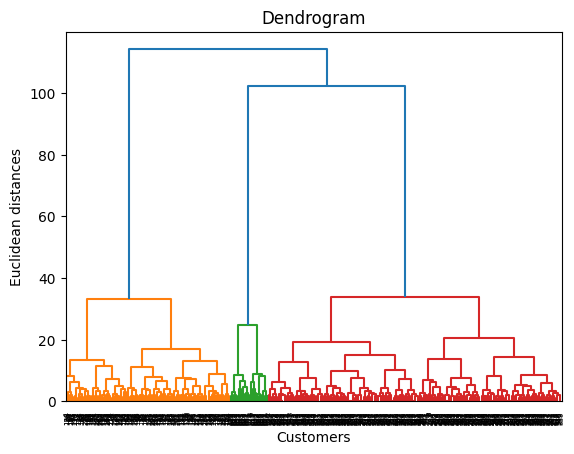

In [ ]:
# Build dendogram
import scipy.cluster.hierarchy as sch

# Build dendogram using ward distance
# more info - https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html
dendrogram = sch.dendrogram(sch.linkage(X, method = 'ward'))

# Plot
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [ ]:
# Build Cluster using Agglomerative Method
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 5, metric = 'euclidean', linkage = 'ward')
y_hc = hc.fit_predict(X)

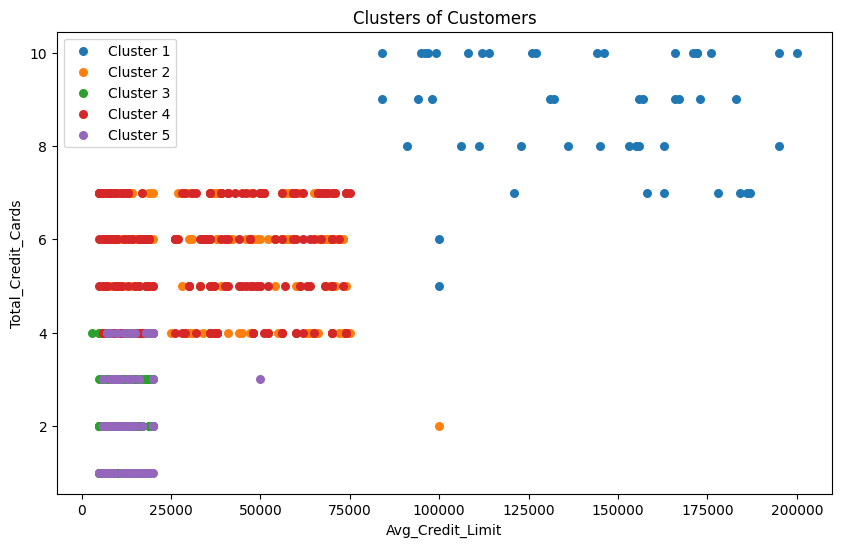

In [ ]:
# Hasil clustering divisualisasikan dengan 2 kolom asli dari dataset
# Warnanya menunjukkan cluster dari model Agglomerative sebelumnya
plt.figure(figsize=(10, 6))

for i in range(5):
    plt.scatter(
        df.loc[y_hc == i, 'Avg_Credit_Limit'],
        df.loc[y_hc == i, 'Total_Credit_Cards'],
        s=30,
        label=f'Cluster {i + 1}'
    )

plt.title('Clusters of Customers')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

# Evaluate the clustering using silhouette coefficient
silhouette_avg = silhouette_score(X, y_hc)
print(f'Silhouette Coefficient: {silhouette_avg}')

Silhouette Coefficient: 0.2844526687401712


In [ ]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, y_hc)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.2268256734486251
